### Statistical Analysis of Bike Sharing Demand

**Module:** Statistical Techniques for Data Analytics CA1  
**Dataset:** Bike Sharing Dataset: UCI Machine Learning Repository  
**GitHub Repository:** https://github.com/LucianaHamaji-2026408/CCT_Statistics_CA01_2026408

### Introduction

The Bike Sharing Dataset contains hourly records of bicycle rentals from the Capital Bikeshare system in Washington, D.C., during 2011 and 2012. It includes information about rental demand, weather conditions, temperature, humidity, and time-related factors.

### Problem Definition

Bike rental demand varies throughout the day and under different weather conditions. Understanding these variations can help identify patterns in bicycle usage and evaluate how statistical distributions represent the observed data.

### Project Objective

The aim of this project is to explore bike rental patterns using descriptive statistics and data visualisations. The analysis will also apply Binomial, Poisson, and Normal distributions to investigate probabilities, evaluate their suitability for selected variables, and discuss their limitations.

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [30]:
df = pd.read_csv("hour.csv")

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [31]:
df.shape

(17379, 17)

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


In [33]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [34]:
df.duplicated().sum()

np.int64(0)

### Data Quality Assessment

The dataset was checked for missing values and duplicate records using Python. No missing values or fully duplicated rows were identified across the 17 columns.

Therefore, no removal or imputation of missing values was required. Further checks of variable types and values will be considered during the analysis.

The meteorological variables are already normalised in the original dataset: temperature is divided by 41, humidity by 100, and wind speed by 67, as documented by UCI. Therefore, no additional normalisation was required for this analysis.

In [35]:
df[['cnt', 'temp', 'hum', 'windspeed']].describe().round(2)

,cnt,temp,hum,windspeed
count,17379.00,17379.00,17379.00,17379.00
mean,189.46,0.50,0.63,0.19
std,181.39,0.19,0.19,0.12
min,1.00,0.02,0.00,0.00
25%,40.00,0.34,0.48,0.10
50%,142.00,0.50,0.63,0.19
75%,281.00,0.66,0.78,0.25
max,977.00,1.00,1.00,0.85


### Interpretation of Descriptive Statistics

The dataset contains 17,379 hourly observations. The average number of bike rentals was 189.46 per hour, while the median was 142, suggesting a positively skewed distribution. The relatively high standard deviation (181.39) indicates considerable variability in rental demand.

Temperature and humidity had normalised mean values of 0.50 and 0.63, respectively. Wind speed had a lower mean of 0.19. These descriptive statistics provide an initial overview of rental demand and weather conditions, while further visualisations will help identify patterns and assess the shape of the distributions.

In [36]:
df[['cnt', 'temp', 'hum', 'windspeed']].skew().round(2)

cnt          1.28
temp        -0.01
hum         -0.11
windspeed    0.57
dtype: float64

### Skewness Analysis

The number of bike rentals (`cnt`) shows positive skewness (1.28), indicating a longer right tail and some hours with unusually high rental demand.

Temperature (-0.01) and humidity (-0.11) are approximately symmetric in terms of skewness, while wind speed (0.57) shows moderate positive skewness.

These results help describe the shape of the variables and suggest that temperature may be suitable for further investigation using the Normal distribution. However, additional visual analysis is necessary to assess whether the data follow a normal pattern.

### Distribution of Hourly Bike Rentals

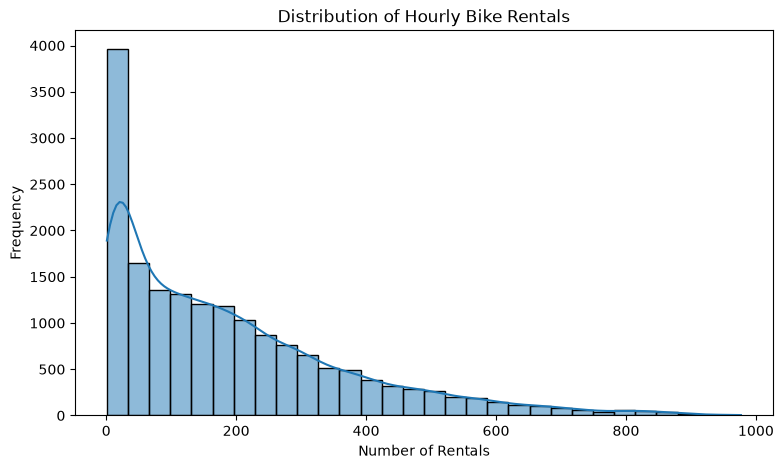

In [37]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df,x='cnt',bins=30,kde=True)

plt.title('Distribution of Hourly Bike Rentals')
plt.xlabel('Number of Rentals')
plt.ylabel('Frequency')

plt.show()

### Interpretation – Distribution of Hourly Bike Rentals

The histogram shows a positively skewed distribution, with most observations concentrated at lower rental counts and a long tail extending towards higher values. This is consistent with the skewness value of 1.28 and the mean (189.46) being higher than the median (142).

The histogram was selected to visualise the frequency distribution of hourly rentals, while the KDE curve helps illustrate its overall shape. The results indicate considerable variation in rental demand across the observed hours.

### Average Bike Rentals by Hour

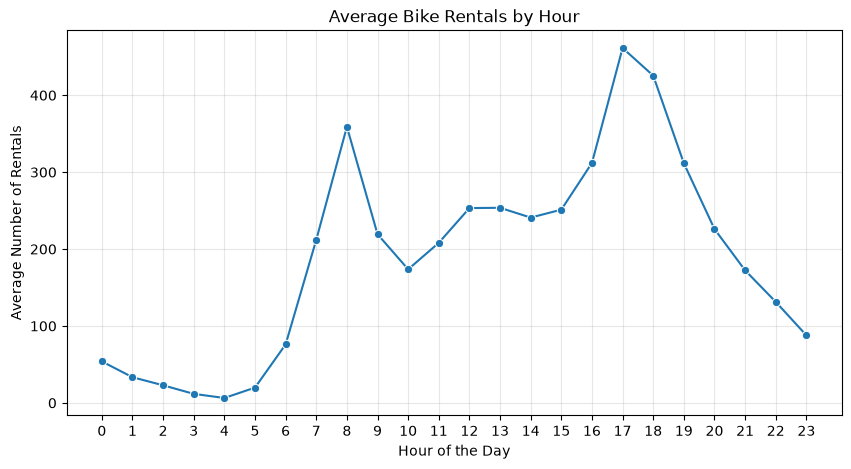

In [38]:
# Calculate average bike rentals for each hour
hourly_avg = df.groupby('hr')['cnt'].mean()

# Create the chart
plt.figure(figsize=(10, 5))

sns.lineplot(x=hourly_avg.index, y=hourly_avg.values, marker='o')

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Number of Rentals')

plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

### Interpretation – Average Bike Rentals by Hour

The line chart shows clear variations in average bike rental demand throughout the day. The lowest demand occurs around 4 AM, while two main peaks appear at 8 AM and 5 PM, with approximately 359 and 461 rentals per hour, respectively.

These patterns may be associated with commuting hours, although the dataset does not directly confirm the reasons for bicycle use. The chart was selected to illustrate how rental demand changes over time and to help explain the variability observed in the overall distribution.

### Distribution of Bike Rentals by Season

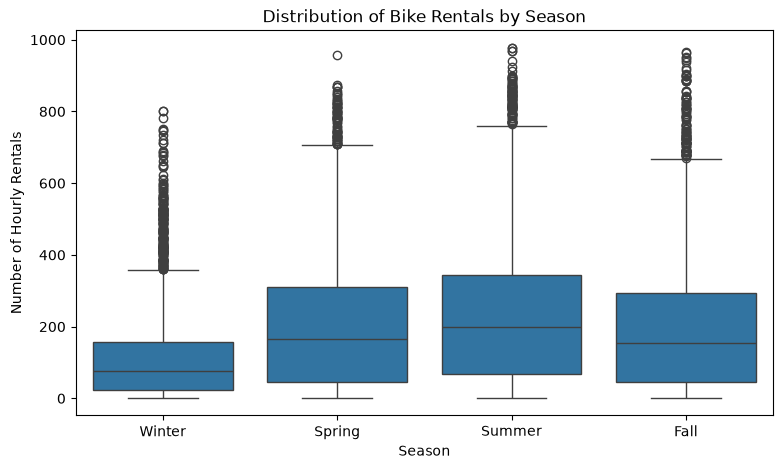

In [40]:
season_names = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}

df['season_name'] = df['season'].map(season_names)

plt.figure(figsize=(9, 5))

sns.boxplot(data=df,x='season_name',y='cnt',order=['Winter', 'Spring', 'Summer', 'Fall'])

plt.title('Distribution of Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Number of Hourly Rentals')

plt.show()

In [41]:
season_stats = df.groupby('season_name')['cnt'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

season_stats = season_stats.reindex(['Winter', 'Spring', 'Summer', 'Fall'])

season_stats

,count,mean,median,std,min,max
season_name,,,,,,
Winter,4242,111.11,76.0,119.22,1,801
Spring,4409,208.34,165.0,188.36,1,957
Summer,4496,236.02,199.0,197.71,1,977
Fall,4232,198.87,155.5,182.97,1,967


### Interpretation – Distribution of Bike Rentals by Season

The boxplot and descriptive statistics reveal seasonal differences in hourly bike rental demand. Summer has the highest mean (236.02) and median (199), while winter has the lowest mean (111.11) and median (76).

Summer also shows the highest standard deviation (197.71), indicating greater absolute variability in rental counts. In all four seasons, the mean exceeds the median, suggesting positively skewed distributions.

These findings indicate an association between season and bike rental demand. However, other factors, including weather conditions, working days and time of day, may also contribute to these patterns.

### Binomial Distribution

In [71]:
daily_data = df.drop_duplicates(subset='dteday')

p_daily = daily_data['workingday'].mean()

print("Working day probability:", round(p_daily, 4))

Working day probability: 0.684


### Binomial Distribution – Probability Calculation

The Binomial distribution is used to calculate the probability of a specific number of successes in a fixed number of independent trials.

In this analysis, a success represents a working day. The estimated probability of success is p = 0.684, based on the proportion of unique working days in the dataset.

For a hypothetical sample of 10 independently selected days, the probability of exactly 7 working days is calculated using:

$$
P(X=k)=\binom{n}{k}p^k(1-p)^{n-k}
$$

Where:
- n = 10 (number of trials)
- k = 7 (number of working days)
- p = 0.684 (probability of success)

In [78]:
from scipy.stats import binom

# Binomial parameters
n = 10
p = p_daily
k = 7

# Calculate probability
binomial_probability = binom.pmf(k, n, p)

# Calculate expected value
expected_value = n * p

print("P(X = 7):", round(binomial_probability, 4))
print("Probability (%):", round(binomial_probability * 100, 2))
print("Expected value:", round(expected_value, 2))

P(X = 7): 0.2652
Probability (%): 26.52
Expected value: 6.84


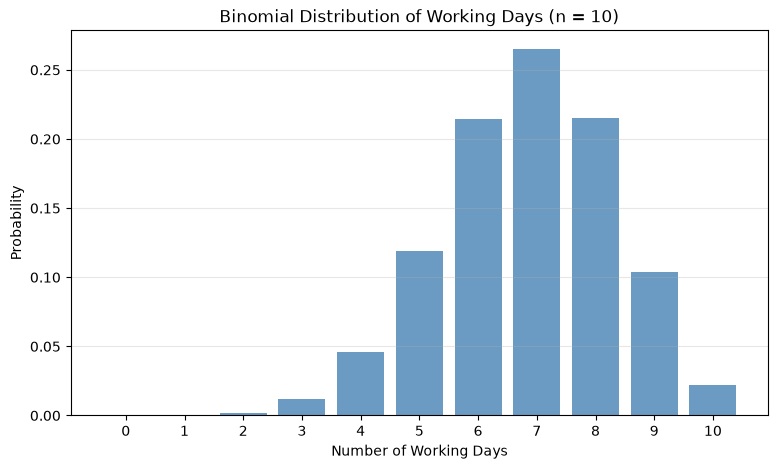

In [79]:
# Possible number of working days
x = np.arange(0, n + 1)

# Calculate Binomial probabilities
binomial_probs = binom.pmf(x, n, p)

# Plot
plt.figure(figsize=(9, 5))

plt.bar(
    x,
    binomial_probs,
    color='steelblue',
    alpha=0.8
)

plt.title('Binomial Distribution of Working Days (n = 10)')
plt.xlabel('Number of Working Days')
plt.ylabel('Probability')
plt.xticks(range(0, n + 1))
plt.grid(axis='y', alpha=0.3)

plt.show()

### Large Sample Behaviour – Binomial Distribution

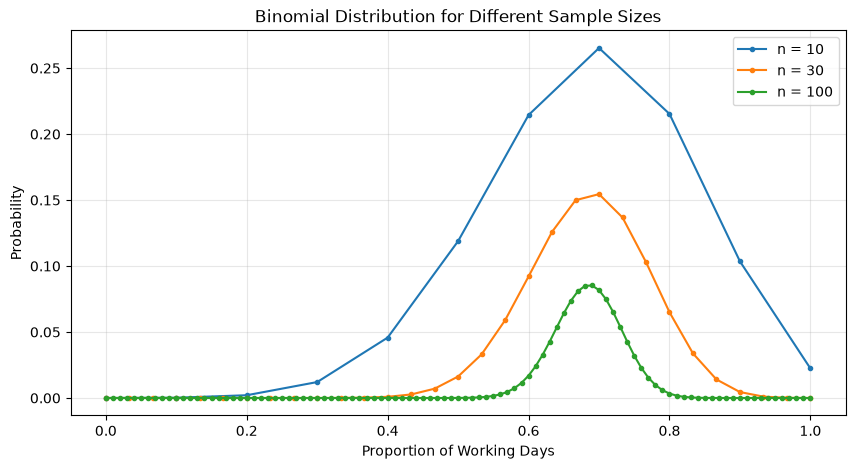

In [80]:
from scipy.stats import binom
import numpy as np
import matplotlib.pyplot as plt

# Estimated probability of a working day
p = p_daily

# Different sample sizes
sample_sizes = [10, 30, 100]

plt.figure(figsize=(10, 5))

for n in sample_sizes:
    x = np.arange(0, n + 1)
    probabilities = binom.pmf(x, n, p)

    plt.plot(
        x / n,
        probabilities,
        marker='o',
        markersize=3,
        label=f'n = {n}'
    )

plt.title('Binomial Distribution for Different Sample Sizes')
plt.xlabel('Proportion of Working Days')
plt.ylabel('Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretation – Binomial Distribution

The binomial distribution models the number of working days in a hypothetical sample of 10 independently selected days, using an estimated success probability of 0.684 from the dataset.

The highest probability occurs at 7 working days (26.52%), which is close to the expected value of 6.84. The distribution is slightly left-skewed, with lower probabilities at the extremes.

This model assumes independent trials and a constant probability of success. These assumptions may not hold for consecutive calendar days, so the results should be interpreted as a simplified probability model.

As the sample size increases from 10 to 100, the distribution of the proportion of working days becomes more concentrated around the expected value of 0.684. The variability decreases, and the distribution becomes more symmetric. This demonstrates how larger samples can produce more stable proportions, assuming independent trials and a constant probability of success.

### Poisson Distribution

In [64]:
poisson_mean = df['cnt'].mean()
poisson_variance = df['cnt'].var()

print("Mean:", round(poisson_mean, 2))
print("Variance:", round(poisson_variance, 2))
print("Variance / Mean:", round(poisson_variance / poisson_mean, 2))

Mean: 189.46
Variance: 32901.46
Variance / Mean: 173.66


### Poisson Distribution – Initial Assessment

The mean number of hourly bike rentals is 189.46, while the variance is 32,901.46. The variance-to-mean ratio is 173.66, indicating substantial overdispersion.

Since a Poisson distribution assumes equal theoretical mean and variance, these results suggest that a single Poisson model may not adequately represent the overall rental counts.

One possible explanation is the considerable variation in demand throughout the day, particularly between overnight hours and commuting periods.

In [65]:
# Select bike rentals recorded at 4 AM
rentals_4am = df[df['hr'] == 4]['cnt']

# Calculate descriptive statistics
mean_4am = rentals_4am.mean()
variance_4am = rentals_4am.var()

print("Number of observations:", len(rentals_4am))
print("Mean:", round(mean_4am, 2))
print("Variance:", round(variance_4am, 2))
print("Variance / Mean:", round(variance_4am / mean_4am, 2))

Number of observations: 697
Mean: 6.35
Variance: 17.17
Variance / Mean: 2.7


In [66]:
from scipy.stats import poisson

# Mean rentals at 4 AM
lambda_4am = rentals_4am.mean()

# Number of rentals to investigate
x = 6

# Calculate Poisson probability
probability = poisson.pmf(x, mu=lambda_4am)

print("Lambda:", round(lambda_4am, 2))
print("P(X = 6):", round(probability, 4))
print("Probability (%):", round(probability * 100, 2))

Lambda: 6.35
P(X = 6): 0.159
Probability (%): 15.9


In [67]:
# Observed frequency of exactly 6 rentals
observed_count = (rentals_4am == 6).sum()

# Observed probability
observed_probability = (rentals_4am == 6).mean()

print("Observations with exactly 6 rentals:", observed_count)
print("Observed probability:", round(observed_probability, 4))
print("Observed probability (%):", round(observed_probability * 100, 2))
print("Poisson probability (%):", round(probability * 100, 2))

Observations with exactly 6 rentals: 76
Observed probability: 0.109
Observed probability (%): 10.9
Poisson probability (%): 15.9


### Observed vs Poisson Distribution

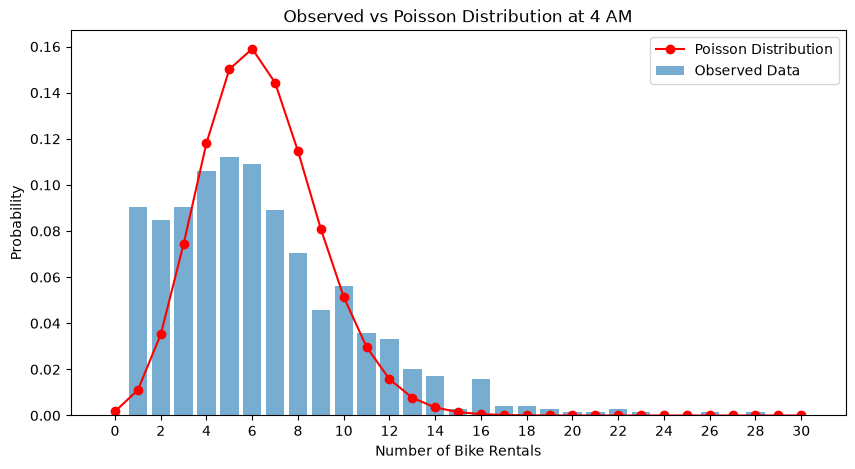

In [68]:
from scipy.stats import poisson

# Values of possible rental counts
x_values = np.arange(0, 31)

# Observed probabilities
observed = rentals_4am.value_counts(normalize=True)
observed = observed.reindex(x_values, fill_value=0)

# Theoretical Poisson probabilities
expected = poisson.pmf(x_values, mu=lambda_4am)

# Plot
plt.figure(figsize=(10, 5))

plt.bar(
    x_values,
    observed,
    alpha=0.6,
    label='Observed Data'
)

plt.plot(
    x_values,
    expected,
    marker='o',
    color='red',
    label='Poisson Distribution'
)

plt.title('Observed vs Poisson Distribution at 4 AM')
plt.xlabel('Number of Bike Rentals')
plt.ylabel('Probability')
plt.xticks(range(0, 31, 2))
plt.legend()
plt.show()

### Interpretation – Observed vs Poisson Distribution

The chart compares the observed distribution of hourly bike rentals at 4 AM with a theoretical Poisson distribution using λ = 6.35.

The Poisson model assigns higher probabilities to values close to the mean, while the observed data show more frequent low rental counts and a longer right tail. For example, the theoretical probability of exactly six rentals is 15.9%, compared with an observed proportion of 10.9%.

These differences, together with the variance-to-mean ratio of 2.70, indicate overdispersion and suggest that a simple Poisson distribution does not fully capture the variability in rental demand.

Although focusing on 4 AM reduced the variance-to-mean ratio from 173.66 to 2.70, the remaining overdispersion indicates that the Poisson model still does not fully capture the observed variability.

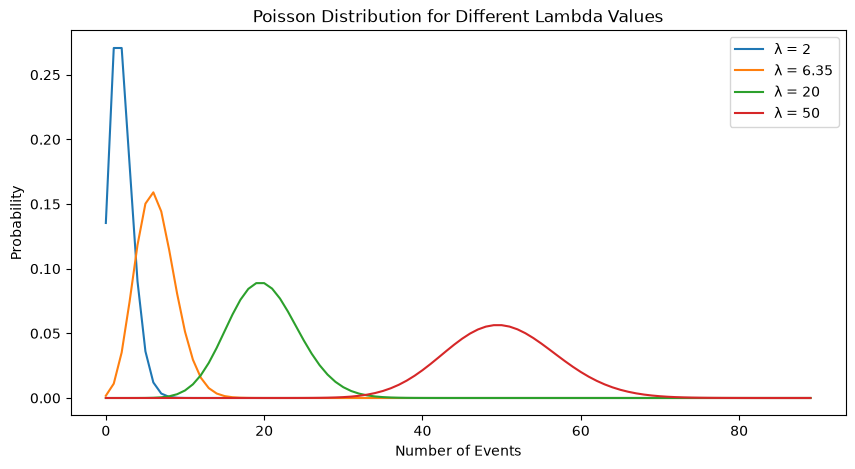

In [87]:
from scipy.stats import poisson
import numpy as np
import matplotlib.pyplot as plt

lambda_values = [2, 6.35, 20, 50]

plt.figure(figsize=(10, 5))

for lam in lambda_values:
    x = np.arange(0, 90)
    plt.plot(x, poisson.pmf(x, mu=lam),
             label=f'λ = {lam}')

plt.title('Poisson Distribution for Different Lambda Values')
plt.xlabel('Number of Events')
plt.ylabel('Probability')
plt.legend()
plt.show()

The graph illustrates how the theoretical Poisson distribution changes as λ increases. For smaller values of λ, the distribution is positively skewed. As λ increases, the distribution becomes more symmetric and approaches a Normal distribution. However, this theoretical approximation does not eliminate the overdispersion observed in the actual bike rental data.

### Large Sample Behaviour – Poisson Analysis

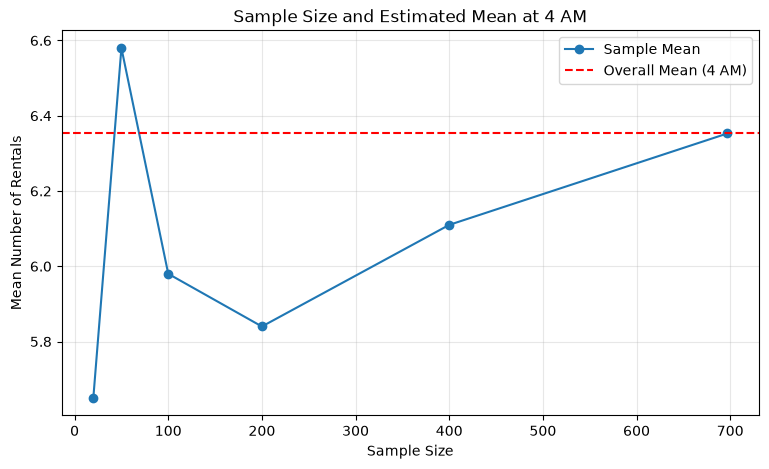

In [74]:
# Compare estimated means across sample sizes
sample_sizes = [20, 50, 100, 200, 400, 697]

sample_means = []

for n in sample_sizes:
    sample = rentals_4am.sample(n=n, random_state=42)
    sample_means.append(sample.mean())

plt.figure(figsize=(9, 5))

plt.plot(sample_sizes, sample_means, marker='o',
         label='Sample Mean')

plt.axhline(
    y=rentals_4am.mean(),
    color='red',
    linestyle='--',
    label='Overall Mean (4 AM)'
)

plt.title('Sample Size and Estimated Mean at 4 AM')
plt.xlabel('Sample Size')
plt.ylabel('Mean Number of Rentals')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretation – Large Sample Behaviour

The chart illustrates how the estimated mean of bike rentals at 4 AM varies across different sample sizes. Smaller samples produced different mean estimates, while the full dataset of 697 observations had a mean of approximately 6.35 rentals.

This illustrates how sample size can influence the estimation of the Poisson parameter (λ). Larger samples generally provide more precise estimates, although the results from individual samples may fluctuate.

However, increasing the sample size does not necessarily improve the fit of the Poisson model, as overdispersion remains present in the observed data.

In [72]:
# Normal Distribution - Temperature

# Calculate mean and standard deviation
temp_mean = df['temp'].mean()
temp_std = df['temp'].std()

# Calculate skewness
temp_skew = df['temp'].skew()

print("Mean:", round(temp_mean, 4))
print("Standard deviation:", round(temp_std, 4))
print("Skewness:", round(temp_skew, 4))

Mean: 0.497
Standard deviation: 0.1926
Skewness: -0.006


### Normal Distribution – Temperature Analysis

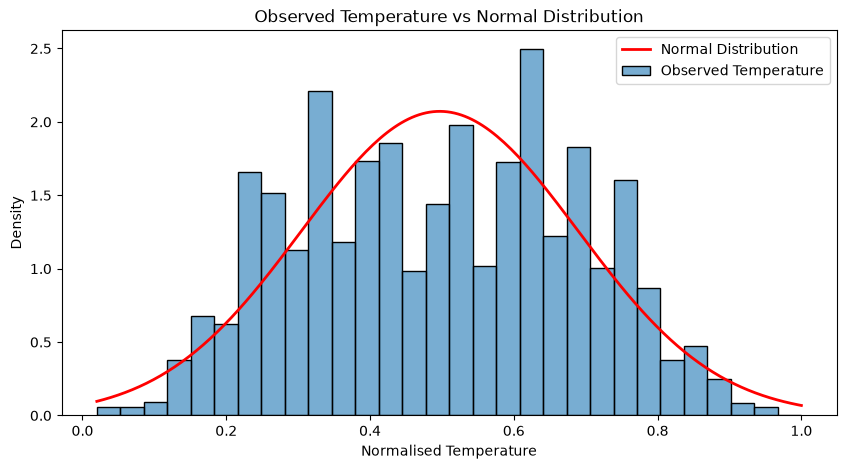

In [73]:
from scipy.stats import norm

# Normal distribution parameters
mu = df['temp'].mean()
sigma = df['temp'].std()

# Values for the theoretical Normal curve
x = np.linspace(df['temp'].min(), df['temp'].max(), 200)

# Normal probability density
normal_curve = norm.pdf(x, loc=mu, scale=sigma)

# Plot
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='temp',
    bins=30,
    stat='density',
    alpha=0.6,
    label='Observed Temperature'
)

plt.plot(
    x,
    normal_curve,
    color='red',
    linewidth=2,
    label='Normal Distribution'
)

plt.title('Observed Temperature vs Normal Distribution')
plt.xlabel('Normalised Temperature')
plt.ylabel('Density')
plt.legend()

plt.show()

### Interpretation – Normal Distribution

The histogram shows that normalised temperature values are approximately symmetric, with a mean of 0.497, a standard deviation of 0.1926 and skewness of -0.006.

The theoretical Normal curve provides a reasonable approximation of the overall distribution, although the observed data show irregularities and multiple local peaks that are not captured by the model.

Furthermore, temperature is normalised and bounded between 0 and 1, whereas the Normal distribution is theoretically unbounded. Therefore, the Normal model should be interpreted as an approximation rather than a perfect fit.

In [75]:
from scipy.stats import norm

# Temperature threshold
x_value = 0.60

# Calculate Z-score
z_score = (x_value - temp_mean) / temp_std

# Calculate theoretical probability
normal_probability = norm.cdf(
    x_value,
    loc=temp_mean,
    scale=temp_std
)

print("Z-score:", round(z_score, 4))
print("P(X < 0.60):", round(normal_probability, 4))
print("Probability (%):", round(normal_probability * 100, 2))

Z-score: 0.535
P(X < 0.60): 0.7037
Probability (%): 70.37


In [76]:
# Observed probability of temperature below 0.60
observed_normal = (df['temp'] < 0.60).mean()

# Compare observed and theoretical probabilities
print("Observed probability (%):",
      round(observed_normal * 100, 2))

print("Normal probability (%):",
      round(normal_probability * 100, 2))

print("Difference (percentage points):",
      round(abs(observed_normal - normal_probability) * 100, 2))

Observed probability (%): 62.54
Normal probability (%): 70.37
Difference (percentage points): 7.83


### Interpretation – Normal Probability Comparison

Using a Normal distribution with a mean of 0.497 and a standard deviation of 0.1926, the theoretical probability of a normalised temperature below 0.60 is 70.37%. However, the observed proportion in the dataset is 62.54%, representing a difference of 7.83 percentage points.

Although the temperature distribution is approximately symmetric (skewness = -0.006), the histogram and probability comparison indicate that the Normal model does not perfectly represent the observed data.

This suggests that the Normal distribution may provide a useful approximation of the overall temperature pattern, but its limitations should be considered when estimating probabilities.

### Binomial vs Normal Approximation

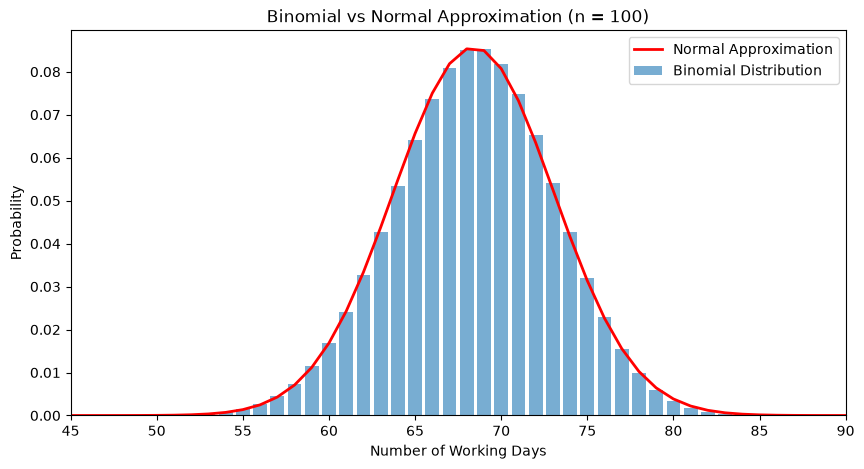

In [86]:
from scipy.stats import binom, norm

# Binomial parameters
n = 100
p = p_daily

# Mean and standard deviation
mu_bin = n * p
sigma_bin = np.sqrt(n * p * (1 - p))

# Possible number of working days
x = np.arange(0, n + 1)

# Binomial probabilities
binomial_probs = binom.pmf(x, n, p)

# Normal approximation using continuity correction
normal_probs = norm.cdf(
    x + 0.5, loc=mu_bin, scale=sigma_bin
) - norm.cdf(
    x - 0.5, loc=mu_bin, scale=sigma_bin
)

# Plot
plt.figure(figsize=(10, 5))

plt.bar(
    x,
    binomial_probs,
    alpha=0.6,
    label='Binomial Distribution'
)

plt.plot(
    x,
    normal_probs,
    color='red',
    linewidth=2,
    label='Normal Approximation'
)

plt.title('Binomial vs Normal Approximation (n = 100)')
plt.xlabel('Number of Working Days')
plt.ylabel('Probability')
plt.xlim(45, 90)
plt.legend()
plt.show()

### Interpretation – Normal Approximation to the Binomial Distribution

The graph compares the exact Binomial distribution with its Normal approximation for n = 100 and p = 0.684.

The two distributions show a very similar shape, with probabilities concentrated around the expected value of 68.4 working days. The Normal approximation closely follows the Binomial probabilities, particularly near the centre of the distribution.

Since both np = 68.4 and n(1 − p) = 31.6 exceed 10, the conditions for a reasonable Normal approximation are satisfied. The continuity correction also improves the comparison between the discrete and continuous distributions.

This demonstrates how the Binomial distribution can be approximated by the Normal distribution when the number of independent trials is sufficiently large.

### Comparison of Statistical Distributions

The three distributions were applied to different characteristics of the Bike Sharing Dataset. The Binomial distribution was used to model the number of working days in a fixed sample, while the Poisson distribution was applied to hourly bike rental counts. The Normal distribution was used to approximate the distribution of normalised temperature.

Each model has different assumptions and limitations. The Binomial distribution requires independent trials and a constant probability of success. The Poisson model assumes equal theoretical mean and variance, but the observed rental counts showed overdispersion. Although temperature was approximately symmetric, the Normal model did not perfectly represent its observed distribution.

The analysis also demonstrated that the Normal distribution can provide a close approximation to the Binomial distribution when the number of trials is sufficiently large and the expected numbers of successes and failures are both sufficiently high.

The Poisson distribution can also be approximated by a Normal distribution when its mean (λ) is sufficiently large. However, the observed bike rental data showed overdispersion, meaning that a simple Poisson model did not adequately represent the variability in demand. Therefore, a Normal approximation to that Poisson model would not necessarily provide a good fit to the observed data.

Overall, these findings highlight the importance of considering variable type, distribution shape and statistical assumptions when selecting a probability model.